In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [2]:
df=pd.read_csv('./height-weight.csv')

In [3]:
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


Text(0.5, 1.0, 'Height vs Weight')

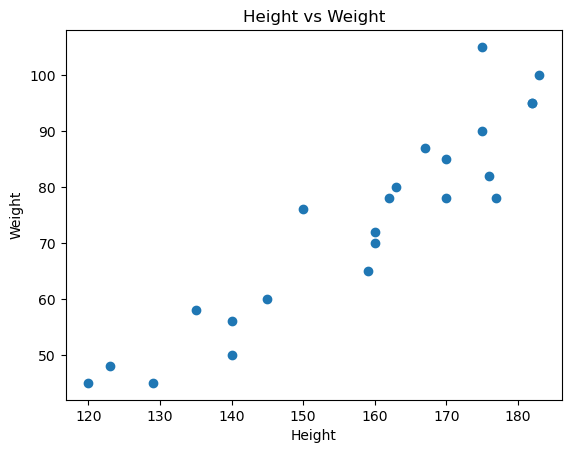

In [4]:
# Scatter plot to visualize the data
plt.scatter(df['Height'], df['Weight'])
plt.xlabel('Height')
plt.ylabel('Weight')
plt.title('Height vs Weight')

In [5]:
# Correlation
df.corr()

,Weight,Height
Weight,1.000000,0.931142
Height,0.931142,1.000000


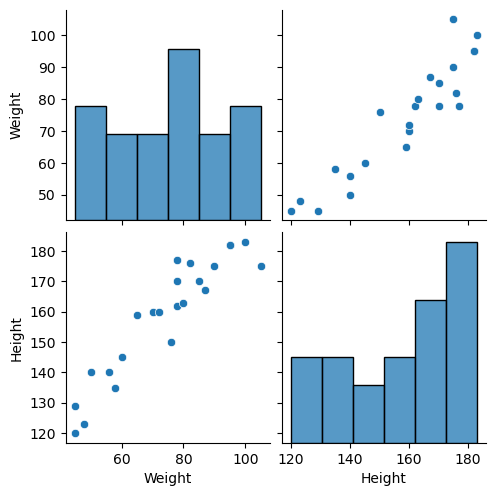

In [6]:
# Seaborn for visualization

import seaborn as sns
sns.pairplot(df)

In [7]:
# # Independent and dependent variables
X = df[['Weight']] ## Independent features should be in 2D array
Y = df['Height'] ## Dependent feature can be in 1D array or series

In [8]:
# Train test split
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.25, random_state=42) ## Random state is used to get the same split every time we run the code

In [9]:
X_train.shape

(17, 1)

In [10]:
Y_train.shape

(17,)

In [11]:
# Standardization
# z-score normalization - (x - mean) / std
from sklearn.preprocessing import StandardScaler

In [12]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)

In [13]:
X_test=scaler.transform(X_test) ## We use transform here because we want to use the same scaler that we fitted on the training data

In [14]:
# Apply Simple Linear Regression
from sklearn.linear_model import LinearRegression
regression= LinearRegression()

In [15]:
from time import time
start_time = time()
regression.fit(X_train, Y_train)
end_time = time()
print(f"Training time: {end_time - start_time} seconds")

Training time: 0.02265477180480957 seconds


In [16]:
print("Coefficient or slope :",regression.coef_)

Coefficient or slope : [17.2982057]


In [17]:
print("Intercept :", regression.intercept_)

Intercept : 156.47058823529412


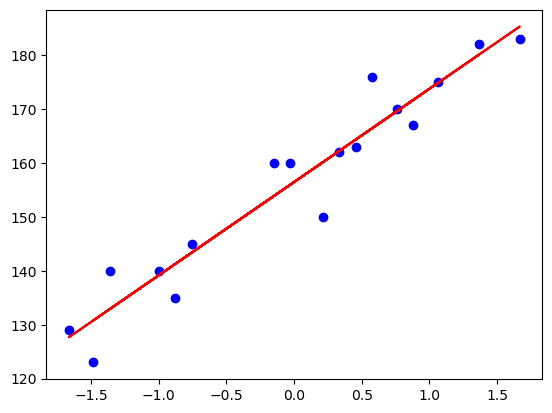

In [20]:
# Plot training data best fit line
plt.scatter(X_train, Y_train, color='blue', label='Training Data')
plt.plot(X_train, regression.predict(X_train), color='red', label='Best Fit Line')

### Prediction of test data

1. Predicted height output = intercept + coef_(weight)
2. y_pred_test = 156.47 + 17.29(X_test)

In [23]:
# Predicting the test set results
Y_pred=regression.predict(X_test)

In [24]:
# Performance metrics

from sklearn.metrics import mean_squared_error, mean_absolute_error

mse = mean_squared_error(Y_test, Y_pred)
mae = mean_absolute_error(Y_test, Y_pred)
rmse= np.sqrt(mse)
print(f"Mean Squared Error: {mse}")
print(f"Mean Absolute Error: {mae}")
print(f"Root Mean Squared Error: {rmse}")

Mean Squared Error: 114.84069295228699
Mean Absolute Error: 9.665125886795005
Root Mean Squared Error: 10.716374991212605


R Square
R² = 1 - (SS_res / SS_tot)
Where:
- SS_res is the sum of squares of residuals (the differences between observed and predicted values).
- SS_tot is the total sum of squares (the differences between observed values and the mean of observed values).

In [25]:
from sklearn.metrics import r2_score
r2 = r2_score(Y_test, Y_pred)
print(f"R² Score: {r2}")

R² Score: 0.7360826717981276


## Adjusted R Square
Adjusted R² = 1 - [(1 - R²) * (n - 1) / (n - p - 1)]
Where:  
- R² is the coefficient of determination.
- n is the number of observations.
- p is the number of predictors (independent variables) in the model.

In [ ]:
# Adjusted R Square
n = len(Y_test)
p = X_test.shape[1]

adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
print(adjusted_r2)


0.6701033397476595


In [29]:
# OLS - Ordinary Least Squares is a method for estimating the parameters in a linear regression model. It minimizes the sum of the squared differences between the observed dependent variable and those predicted by the linear function of the independent variable.

import statsmodels.api as sm
X_train_sm = sm.add_constant(X_train) ## Adding a constant term to the independent variable
model = sm.OLS(Y_train, X_train_sm).fit()
prediction = model.predict(X_train_sm)
print(model.summary())  
print(prediction)

                            OLS Regression Results                            
Dep. Variable:                 Height   R-squared:                       0.921
Model:                            OLS   Adj. R-squared:                  0.916
Method:                 Least Squares   F-statistic:                     174.5
Date:                Fri, 17 Apr 2026   Prob (F-statistic):           1.15e-09
Time:                        22:18:22   Log-Likelihood:                -51.726
No. Observations:                  17   AIC:                             107.5
Df Residuals:                      15   BIC:                             109.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        156.4706      1.310    119.477      0.0

In [32]:
# Prediction for new data point
regression.predict(scaler.transform([[72]]))

c:\Users\pradn\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([155.97744705])

NOTE : Scaling transformation should be applied to the new data point before making a prediction using the regression model.